# Isolation Forest removal and classification

Use the same 30,000 training rows and five folds as notebooks 03/04.
Isolation Forest is fitted on the 33-feature preprocessed training part of each fold.
Only training rows are removed. MI and classifier preprocessing are refitted
on retained rows. Every validation row is evaluated at threshold 0.5.
Classifier settings are fixed to the previous selected settings. No test rows are used.

## 1. Environment, shared folds, and fixed models

In [1]:
from pathlib import Path
import sys
import time
import platform
import json

experiment_started = time.perf_counter()
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.ensemble import IsolationForest
from threadpoolctl import threadpool_info, threadpool_limits
get_ipython().run_line_magic("matplotlib", "inline")
thread_limit = threadpool_limits(limits=1)
cwd = Path.cwd()
repo_root = cwd if (cwd / "src/preprocessing.py").exists() else cwd.parent
assert (repo_root / "src/unsupervised_common.py").exists(), "Open from the repository root or notebooks/."
sys.path.insert(0, str(repo_root / "src"))
from unsupervised_common import (
    MODEL_SPECS, METRICS, WARNING_COLUMNS, load_training_data, run_outlier_cv,
    summarize_outlier_results, paired_outlier_differences,
    check_no_removal_baseline, pca_projection,
)
results_dir = repo_root / "results"
results_dir.mkdir(exist_ok=True)
print(f"Python {platform.python_version()}; sklearn {sklearn.__version__}; pandas {pd.__version__}; numpy {np.__version__}")
data = load_training_data(repo_root)
print(f"CV rows: {len(data.X_dev):,}; original features: {data.X_dev.shape[1]}; folds: {len(data.folds)}")
display(pd.DataFrame([{"model": name, "k": spec["k"], "params": json.dumps(spec["params"])}
                      for name, spec in MODEL_SPECS.items()]))

Python 3.13.3; sklearn 1.9.1; pandas 3.1.1; numpy 2.5.4


CV rows: 30,000; original features: 33; folds: 5


,model,k,params
0,Random Forest,33,"{""n_estimators"": 400, ""max_depth"": 20, ""min_sa..."
1,GaussianNB,5,"{""var_smoothing"": 1e-06}"
2,Logistic Regression,17,"{""C"": 0.1, ""random_state"": 42, ""max_iter"": 100}"
3,k-NN,17,"{""n_neighbors"": 51, ""weights"": ""uniform"", ""n_j..."


## 2. Training-only removal and five-fold evaluation

Use Isolation Forest with 100 trees, random_state=42, and n_jobs=1. Fit each
detector once per fold and share its mask across the four classifiers. Detector
preprocessing and fit_predict are timed separately. Classifier timing matches
notebooks 03/04. Captured fit diagnostics are saved without changing settings.

In [2]:
def make_iforest(contamination):
    return IsolationForest(n_estimators=100, contamination=contamination,
                           random_state=42, n_jobs=1)

CONDITIONS = [("No removal", None), ("Isolation Forest 1%", 0.01), ("Isolation Forest 5%", 0.05)]
runs = {}
for condition, contamination in CONDITIONS:
    print(f"Running {condition}", flush=True)
    runs[condition] = run_outlier_cv(data, make_iforest, contamination, condition)
    fold_results = pd.concat([run["folds"] for run in runs.values()], ignore_index=True)
    removals = pd.concat([run["removals"] for run in runs.values()], ignore_index=True)
    diagnostic_frames = [run["warnings"] for run in runs.values() if not run["warnings"].empty]
    diagnostics = (pd.concat(diagnostic_frames, ignore_index=True) if diagnostic_frames
                   else pd.DataFrame(columns=WARNING_COLUMNS))
    fold_results.to_csv(results_dir / "iforest_cv_folds.csv", index=False)
    removals.to_csv(results_dir / "iforest_removals.csv", index=False)
    diagnostics.to_csv(results_dir / "iforest_fit_diagnostics.csv", index=False)
money = pd.concat([run["money"] for run in runs.values() if not run["money"].empty], ignore_index=True)
members = pd.concat([run["members"] for run in runs.values() if not run["members"].empty], ignore_index=True)
money.to_csv(results_dir / "iforest_money_statistics.csv", index=False)
members.to_csv(results_dir / "iforest_removed_rows.csv", index=False)
lof_folds = pd.read_csv(results_dir / "lof_cv_folds.csv")
iforest_folds = fold_results.loc[fold_results.condition != "No removal"]
combined_cv_folds = pd.concat([lof_folds, iforest_folds], ignore_index=True)
combined_cv_folds.to_csv(results_dir / "outlier_cv_folds.csv", index=False)
print(f"Captured fit diagnostics: {len(diagnostics)}")
if not diagnostics.empty:
    display(diagnostics.groupby(["condition", "phase", "category"]).size().rename("count").reset_index())

Running No removal


Completed No removal, fold 1/5


Completed No removal, fold 2/5


Completed No removal, fold 3/5


Completed No removal, fold 4/5


Completed No removal, fold 5/5


... (9 outputs left out)

Completed Isolation Forest 5%, fold 3/5


Completed Isolation Forest 5%, fold 4/5


Completed Isolation Forest 5%, fold 5/5


Captured fit diagnostics: 0


## 3. No-removal reference checks

LR and k-NN AP are checked fold by fold against the existing best-setting CSV.
RF and GaussianNB mean AP are checked against notebook 03's four-decimal values.
The respective absolute tolerances are 1e-12 and 5e-5.

In [3]:
baseline_checks = check_no_removal_baseline(fold_results, repo_root)
baseline_checks.to_csv(results_dir / "iforest_baseline_checks.csv", index=False)
display(baseline_checks)

,model,fold,actual_AP,reference_AP,absolute_difference,tolerance,matches
0,Logistic Regression,1,0.619944,0.619944,0.000000,1.000000e-12,True
1,Logistic Regression,2,0.602699,0.602699,0.000000,1.000000e-12,True
2,Logistic Regression,3,0.597432,0.597432,0.000000,1.000000e-12,True
3,Logistic Regression,4,0.599831,0.599831,0.000000,1.000000e-12,True
4,Logistic Regression,5,0.616379,0.616379,0.000000,1.000000e-12,True
5,k-NN,1,0.561799,0.561799,0.000000,1.000000e-12,True
6,k-NN,2,0.559352,0.559352,0.000000,1.000000e-12,True
7,k-NN,3,0.541632,0.541632,0.000000,1.000000e-12,True
8,k-NN,4,0.546007,0.546007,0.000000,1.000000e-12,True
9,k-NN,5,0.564987,0.564987,0.000000,1.000000e-12,True


## 4. Metrics and paired fold differences

SD is the sample standard deviation across five folds. Each difference is
removal minus no removal for the same model and fold.

,condition,model,AP_mean,AP_sd,ROC_AUC_mean,ROC_AUC_sd,Accuracy_mean,Accuracy_sd,Precision_mean,Precision_sd,...,F1_mean,F1_sd,TN_mean,TN_sd,FP_mean,FP_sd,FN_mean,FN_sd,TP_mean,TP_sd
0,Isolation Forest 1%,GaussianNB,0.231001,0.007535,0.805033,0.007162,0.595933,0.090870,0.167202,0.029164,...,0.280465,0.041371,3115.8,549.909720,2367.4,550.183878,57.0,8.944272,459.8,8.927486
1,Isolation Forest 1%,Logistic Regression,0.607116,0.010027,0.920265,0.002349,0.933433,0.001809,0.724706,0.019112,...,0.486516,0.020491,5411.2,6.648308,72.0,6.964194,327.4,11.193748,189.4,11.058933
2,Isolation Forest 1%,Random Forest,0.622134,0.017111,0.921594,0.002138,0.933300,0.001769,0.826963,0.015844,...,0.423885,0.023818,5452.4,3.361547,30.8,3.114482,369.4,10.691118,147.4,10.454664
3,Isolation Forest 1%,k-NN,0.554783,0.010154,0.900890,0.005812,0.929700,0.001800,0.746149,0.022414,...,0.405609,0.026815,5434.0,7.211103,49.2,7.155418,372.6,12.934450,144.2,12.716131
4,Isolation Forest 5%,GaussianNB,0.223529,0.014380,0.799409,0.012147,0.545067,0.082102,0.150793,0.022922,...,0.257395,0.031785,2806.2,506.500444,2677.0,506.360543,52.6,14.293355,464.2,14.446453
5,Isolation Forest 5%,Logistic Regression,0.607081,0.010104,0.920125,0.002416,0.933800,0.001609,0.726247,0.015262,...,0.491315,0.019277,5410.8,5.585696,72.4,5.899152,324.8,10.825895,192.0,10.630146
6,Isolation Forest 5%,Random Forest,0.620784,0.017451,0.921363,0.002159,0.933000,0.002031,0.822948,0.016882,...,0.420691,0.027600,5451.8,3.633180,31.4,3.435113,370.6,12.421755,146.2,12.111978
7,Isolation Forest 5%,k-NN,0.553800,0.010453,0.901158,0.005872,0.929867,0.001909,0.750669,0.027835,...,0.406070,0.028959,5435.0,8.860023,48.2,8.871302,372.6,14.188023,144.2,13.917615
8,No removal,GaussianNB,0.224140,0.015238,0.800042,0.014117,0.583800,0.098688,0.163973,0.029950,...,0.276002,0.042850,3041.0,597.040200,2442.2,597.359774,55.0,7.348469,461.8,7.155418
9,No removal,Logistic Regression,0.607257,0.010206,0.920332,0.002313,0.933567,0.001902,0.724866,0.020275,...,0.488597,0.020889,5410.8,6.906519,72.4,7.231874,326.2,11.300442,190.6,11.193748


,condition,model,AP_difference_mean,AP_difference_sd,ROC_AUC_difference_mean,ROC_AUC_difference_sd,Accuracy_difference_mean,Accuracy_difference_sd,Precision_difference_mean,Precision_difference_sd,...,F1_difference_mean,F1_difference_sd,TN_difference_mean,TN_difference_sd,FP_difference_mean,FP_difference_sd,FN_difference_mean,FN_difference_sd,TP_difference_mean,TP_difference_sd
0,Isolation Forest 1%,GaussianNB,0.006861,0.017553,0.004991,0.012593,0.012133,0.017129,0.003229,0.004171,...,0.004463,0.005609,74.8,106.426970,-74.8,106.426970,2.0,3.741657,-2.0,3.741657
1,Isolation Forest 1%,Logistic Regression,-0.000141,0.000466,-0.000067,0.000108,-0.000133,0.000298,-0.000160,0.002767,...,-0.002081,0.002839,0.4,0.547723,-0.4,0.547723,1.2,1.303840,-1.2,1.303840
2,Isolation Forest 1%,Random Forest,-0.001654,0.001422,-0.000209,0.001043,0.000100,0.000480,-0.006609,0.006453,...,0.004821,0.005387,-2.0,1.224745,2.0,1.224745,-2.6,2.073644,2.6,2.073644
3,Isolation Forest 1%,k-NN,0.000028,0.001135,-0.000212,0.000370,-0.000267,0.000149,-0.004192,0.002934,...,-0.002298,0.003029,-0.8,1.095445,0.8,1.095445,0.8,1.483240,-0.8,1.483240
4,Isolation Forest 5%,GaussianNB,-0.000611,0.022967,-0.000633,0.017845,-0.038733,0.133873,-0.013179,0.038253,...,-0.018607,0.054499,-234.8,815.223712,234.8,815.223712,-2.4,12.259690,2.4,12.259690
5,Isolation Forest 5%,Logistic Regression,-0.000176,0.000272,-0.000208,0.000306,0.000233,0.000630,0.001381,0.006802,...,0.002717,0.005440,0.0,1.870829,0.0,1.870829,-1.4,2.509980,1.4,2.509980
6,Isolation Forest 5%,Random Forest,-0.003004,0.001197,-0.000440,0.000902,-0.000200,0.000820,-0.010624,0.010039,...,0.001628,0.009420,-2.6,1.816590,2.6,1.816590,-1.4,3.974921,1.4,3.974921
7,Isolation Forest 5%,k-NN,-0.000956,0.000208,0.000057,0.000625,-0.000100,0.000190,0.000328,0.007652,...,-0.001836,0.006401,0.2,2.774887,-0.2,2.774887,0.8,3.492850,-0.8,3.492850
8,No removal,GaussianNB,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000
9,No removal,Logistic Regression,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000


,condition,model,AP_mean,AP_sd,AP_difference_mean,AP_difference_sd
0,Isolation Forest 1%,GaussianNB,0.231001,0.007535,0.006861,0.017553
1,Isolation Forest 1%,Logistic Regression,0.607116,0.010027,-0.000141,0.000466
2,Isolation Forest 1%,Random Forest,0.622134,0.017111,-0.001654,0.001422
3,Isolation Forest 1%,k-NN,0.554783,0.010154,0.000028,0.001135
4,Isolation Forest 5%,GaussianNB,0.223529,0.014380,-0.000611,0.022967
5,Isolation Forest 5%,Logistic Regression,0.607081,0.010104,-0.000176,0.000272
6,Isolation Forest 5%,Random Forest,0.620784,0.017451,-0.003004,0.001197
7,Isolation Forest 5%,k-NN,0.553800,0.010453,-0.000956,0.000208
8,No removal,GaussianNB,0.224140,0.015238,0.000000,0.000000
9,No removal,Logistic Regression,0.607257,0.010206,0.000000,0.000000


,condition,model,AP_mean,AP_sd,AP_difference_mean,AP_difference_sd
0,Isolation Forest 1%,GaussianNB,0.231001,0.007535,0.006861,0.017553
1,Isolation Forest 1%,Logistic Regression,0.607116,0.010027,-0.000141,0.000466
2,Isolation Forest 1%,Random Forest,0.622134,0.017111,-0.001654,0.001422
3,Isolation Forest 1%,k-NN,0.554783,0.010154,0.000028,0.001135
4,Isolation Forest 5%,GaussianNB,0.223529,0.014380,-0.000611,0.022967
5,Isolation Forest 5%,Logistic Regression,0.607081,0.010104,-0.000176,0.000272
6,Isolation Forest 5%,Random Forest,0.620784,0.017451,-0.003004,0.001197
7,Isolation Forest 5%,k-NN,0.553800,0.010453,-0.000956,0.000208
8,LOF 1%,GaussianNB,0.232401,0.009567,0.008261,0.019995
9,LOF 1%,Logistic Regression,0.607122,0.010448,-0.000135,0.000283


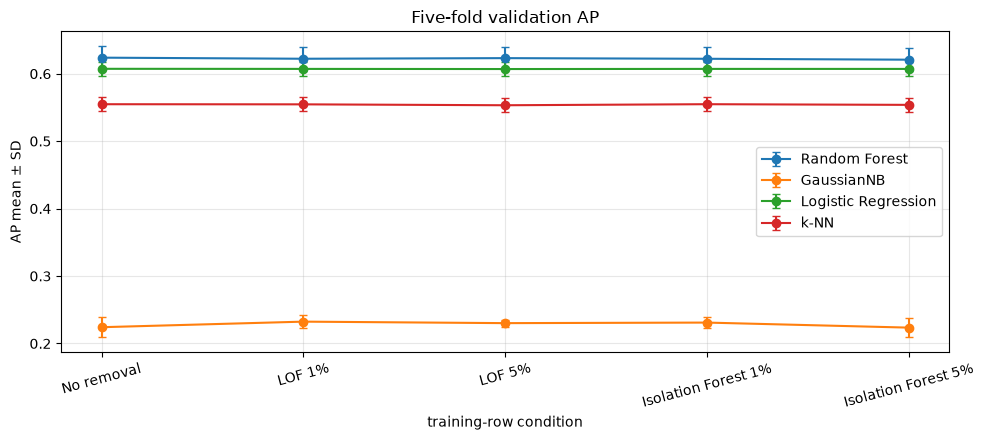

In [4]:
summary = summarize_outlier_results(fold_results)
paired_folds, paired_summary = paired_outlier_differences(fold_results)
summary.to_csv(results_dir / "iforest_cv_summary.csv", index=False)
paired_folds.to_csv(results_dir / "iforest_paired_folds.csv", index=False)
paired_summary.to_csv(results_dir / "iforest_paired_summary.csv", index=False)
metric_columns = [column for metric in METRICS for column in [f"{metric}_mean", f"{metric}_sd"]]
display(summary[["condition", "model"] + metric_columns].round(6))
display(paired_summary.round(6))
ap_table = summary[["condition", "model", "AP_mean", "AP_sd"]].merge(
    paired_summary[["condition", "model", "AP_difference_mean", "AP_difference_sd"]],
    on=["condition", "model"], validate="one_to_one"
)
display(ap_table.round(6))
combined_summary = summarize_outlier_results(combined_cv_folds)
combined_paired_folds, combined_paired_summary = paired_outlier_differences(combined_cv_folds)
combined_summary.to_csv(results_dir / "outlier_cv_summary.csv", index=False)
combined_paired_folds.to_csv(results_dir / "outlier_paired_folds.csv", index=False)
combined_paired_summary.to_csv(results_dir / "outlier_paired_summary.csv", index=False)
combined_ap_table = combined_summary[["condition", "model", "AP_mean", "AP_sd"]].merge(
    combined_paired_summary[["condition", "model", "AP_difference_mean", "AP_difference_sd"]],
    on=["condition", "model"], validate="one_to_one"
)
display(combined_ap_table.round(6))
fig, ax = plt.subplots(figsize=(10, 4.5))
plot_conditions = ["No removal", "LOF 1%", "LOF 5%", "Isolation Forest 1%", "Isolation Forest 5%"]
for name in MODEL_SPECS:
    group = combined_summary.loc[combined_summary.model == name].set_index("condition").loc[plot_conditions]
    ax.errorbar(range(len(plot_conditions)), group.AP_mean, yerr=group.AP_sd,
                marker="o", capsize=3, label=name)
ax.set_xticks(range(len(plot_conditions)), plot_conditions, rotation=15)
ax.set(xlabel="training-row condition", ylabel="AP mean ± SD", title="Five-fold validation AP")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## 5. Actual removal rates and raw monetary summaries

In [5]:
display(removals[["condition", "fold", "contamination", "training_count", "removed_count",
                  "removed_fraction", "training_high_income_rate", "removed_high_income_rate",
                  "retained_high_income_rate"]].round(6))
with pd.option_context("display.max_rows", None):
    display(money.round(4))

,condition,fold,contamination,training_count,removed_count,removed_fraction,training_high_income_rate,removed_high_income_rate,retained_high_income_rate
0,No removal,1,None,24000,0,0.00,0.086125,NaN,0.086125
1,No removal,2,None,24000,0,0.00,0.086125,NaN,0.086125
2,No removal,3,None,24000,0,0.00,0.086125,NaN,0.086125
3,No removal,4,None,24000,0,0.00,0.086125,NaN,0.086125
4,No removal,5,None,24000,0,0.00,0.086167,NaN,0.086167
5,Isolation Forest 1%,1,0.01,24000,240,0.01,0.086125,0.062500,0.086364
6,Isolation Forest 1%,2,0.01,24000,240,0.01,0.086125,0.062500,0.086364
7,Isolation Forest 1%,3,0.01,24000,240,0.01,0.086125,0.083333,0.086153
8,Isolation Forest 1%,4,0.01,24000,240,0.01,0.086125,0.095833,0.086027
9,Isolation Forest 1%,5,0.01,24000,240,0.01,0.086167,0.050000,0.086532


,condition,fold,group,feature,count,mean,std,min,25%,50%,75%,max
0,Isolation Forest 1%,1,removed,wage_per_hour,240.0,91.5208,278.5702,0.0,0.0,0.0,0.0,2050.0
1,Isolation Forest 1%,1,removed,capital_gains,240.0,708.2083,6658.3817,0.0,0.0,0.0,0.0,99999.0
2,Isolation Forest 1%,1,removed,capital_losses,240.0,44.0625,305.2820,0.0,0.0,0.0,0.0,2377.0
3,Isolation Forest 1%,1,removed,dividends_from_stocks,240.0,75.1417,720.9948,0.0,0.0,0.0,0.0,10000.0
4,Isolation Forest 1%,1,retained,wage_per_hour,23760.0,74.1554,313.2770,0.0,0.0,0.0,0.0,8600.0
5,Isolation Forest 1%,1,retained,capital_gains,23760.0,549.3149,5006.1953,0.0,0.0,0.0,0.0,99999.0
6,Isolation Forest 1%,1,retained,capital_losses,23760.0,47.5484,302.0684,0.0,0.0,0.0,0.0,4356.0
7,Isolation Forest 1%,1,retained,dividends_from_stocks,23760.0,238.3247,1827.8077,0.0,0.0,0.0,0.0,99999.0
8,Isolation Forest 1%,2,removed,wage_per_hour,240.0,126.9542,316.6648,0.0,0.0,0.0,0.0,2050.0
9,Isolation Forest 1%,2,removed,capital_gains,240.0,264.1500,1661.3812,0.0,0.0,0.0,0.0,20051.0


## 6. Fold 1 visualization

PCA is fitted to the full preprocessed fold-1 training matrix for visualization
only. Both conditions use the same projection. Validation rows are not plotted.

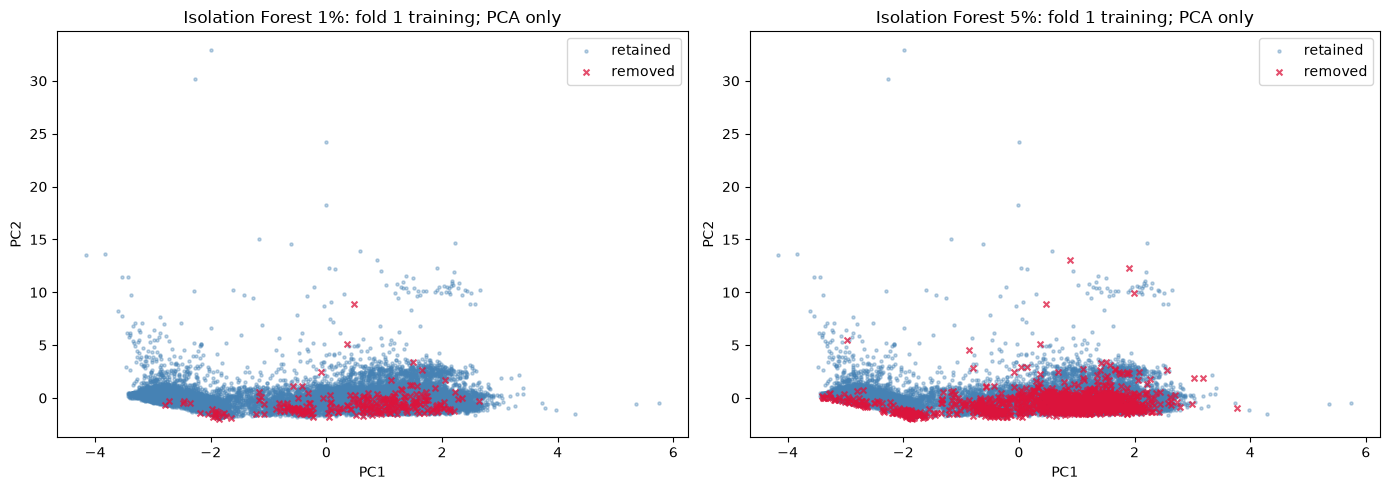

In [6]:
first_one = runs["Isolation Forest 1%"]["first_fold"]
first_five = runs["Isolation Forest 5%"]["first_fold"]
assert np.array_equal(first_one["row_index"], first_five["row_index"])
assert (first_one["Z"] != first_five["Z"]).nnz == 0
coordinates, pca = pca_projection(first_one["Z"])
pd.DataFrame({"component": [1, 2], "explained_variance_ratio": pca.explained_variance_ratio_}).to_csv(
    results_dir / "iforest_pca_variance.csv", index=False
)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, condition in zip(axes, ["Isolation Forest 1%", "Isolation Forest 5%"]):
    mask = runs[condition]["first_fold"]["removed"]
    ax.scatter(coordinates[~mask, 0], coordinates[~mask, 1], s=5, alpha=0.35,
               color="steelblue", label="retained")
    ax.scatter(coordinates[mask, 0], coordinates[mask, 1], s=18, alpha=0.75,
               marker="x", color="crimson", label="removed")
    ax.set(title=f"{condition}: fold 1 training; PCA only", xlabel="PC1", ylabel="PC2")
    ax.legend()
fig.tight_layout()
plt.show()

## 7. Final checks and execution time

In [7]:
assert len(data.X_train) == 172_459 and len(data.X_dev) == 30_000
assert data.X_dev.shape[1] == 33 and len(data.folds) == 5
assert len(fold_results) == 60
assert fold_results.groupby(["condition", "model"]).size().eq(5).all()
assert len(summary) == 12 and len(paired_summary) == 12 and len(paired_folds) == 60
assert len(removals) == 15 and len(money) == 80
assert len(combined_cv_folds) == 100
assert combined_cv_folds.groupby(["condition", "model"]).size().eq(5).all()
assert set(combined_cv_folds.condition) == {
    "No removal", "LOF 1%", "LOF 5%", "Isolation Forest 1%", "Isolation Forest 5%"
}
assert len(combined_paired_folds) == 100
assert fold_results.validation_count.eq(6_000).all()
assert fold_results[["TN", "FP", "FN", "TP"]].sum(axis=1).eq(6_000).all()
assert removals.loc[removals.condition == "No removal", "removed_count"].eq(0).all()
assert np.allclose(removals.removed_fraction, removals.removed_count / 24_000)
for condition, contamination in [("Isolation Forest 1%", 0.01), ("Isolation Forest 5%", 0.05)]:
    observed = removals.loc[removals.condition == condition, "removed_fraction"]
    assert np.allclose(observed, contamination, atol=1 / 24_000, rtol=0)
assert members.groupby(["condition", "fold"]).size().sum() == removals.removed_count.sum()
assert baseline_checks.matches.all()
assert fold_results.loc[fold_results.k == 33, "MI_seconds"].eq(0).all()
assert all(item["num_threads"] == 1 for item in threadpool_info())
total_seconds = time.perf_counter() - experiment_started
pd.DataFrame([{"total_seconds": total_seconds, "captured_fit_diagnostics": len(diagnostics),
               "python": platform.python_version(), "sklearn": sklearn.__version__,
               "pandas": pd.__version__, "numpy": np.__version__, "native_threads": 1}]).to_csv(
    results_dir / "iforest_execution.csv", index=False
)
print("Final checks passed.")
print(f"Total execution time: {total_seconds:.2f} seconds")

Final checks passed.
Total execution time: 207.75 seconds
